# Aegis_net on Google Colab

1. **Runtime -> Change runtime type -> T4 GPU** (the neural models are much faster on a GPU).
2. Run the cells from top to bottom. When asked, upload `Aegis_net.zip` (the project you already have, no need to re-zip anything).
3. Results are written to your Google Drive, so after a disconnect you can run the same cells again and the benchmark **resumes** where it stopped (finished runs are skipped).

In [1]:
# 1) GPU check
!nvidia-smi -L
import torch
print("CUDA available:", torch.cuda.is_available())

GPU 0: NVIDIA A100-SXM4-40GB (UUID: GPU-bf34b551-6a9d-e339-3c07-8751b478704c)
CUDA available: True


In [2]:
# 2) Get the code: upload Aegis_net.zip when the file picker appears
import os, zipfile
from google.colab import files
if not os.path.exists("/content/Aegis_net/main.py"):
    up = files.upload()
    zipfile.ZipFile(next(iter(up))).extractall("/content")
%cd /content/Aegis_net
!ls

Saving Aegis_net (1).zip to Aegis_net (1).zip
/content/Aegis_net
aegis_net	   main.py    requirements.txt	tools
benchmark_outputs  README.md  tests


In [3]:
# 3) Install the libraries (torch is already installed in Colab)
!pip -q install -r requirements.txt

In [4]:
# 4) Google Drive: results are stored here and survive a disconnect
from google.colab import drive
drive.mount("/content/drive")
OUT_ROOT = "/content/drive/MyDrive/aegis_net_outputs"
os.makedirs(OUT_ROOT, exist_ok=True)
print("results go to", OUT_ROOT)

Mounted at /content/drive
results go to /content/drive/MyDrive/aegis_net_outputs


In [5]:
# 5) Smoke test (about 2 minutes): fake data, 3 models, 2 epochs. It only checks that everything works.
!python tools/make_synthetic_data.py --out /content/synthetic --rows 20000
!python main.py --data_path /content/synthetic --out /content/smoke --epochs 2 --seeds 42 --fit_rows 8000 --models LogReg XGBoost Aegis_net --tasks multiclass

label
DDoS-ICMP_Flood    7944
DoS-TCP_Flood      3994
BenignTraffic      3990
Recon-PortScan     2021
BruteForce         1219
SqlInjection        832
[note] epochs=2, seeds=[42]: this is NOT the official protocol (20 epochs, seeds [42, 43, 44, 45, 46]); say so when you report these numbers.
[data] reading 3 file(s) from /content/synthetic
[data] label column: 'label' | numeric features: 30 | text features: 0
[data] rows read: 20,000
[data] rows read 20,000 -> kept 20,000 (duplicates removed 0, label collisions removed 0)
[data] features 30 -> 30 after removing constant / highly correlated columns
[data] classes (6): Benign=3,990, BruteForce=1,219, DDoS=7,944, DoS=3,994, Recon=2,021, Web-based=832
[data] 6 classes ['Benign', 'BruteForce', 'DDoS', 'DoS', 'Recon', 'Web-based'] | 30 features | fit rows 8,000

=== task: multiclass | classes: ['Benign', 'BruteForce', 'DDoS', 'DoS', 'Recon', 'Web-based'] | fit rows 8,000 | test rows 2,910
[1/3] multiclass / LogReg         seed 42: F1 macro 0.

## Choose ONE dataset (run only the cell you need)

All three cells run **every one of the 15 models** and finish with the final comparison:
the 2 strongest ML models + the 2 strongest DL models + Aegis_net (`finalists.md` and `finalists_per_class.png`).

In [ ]:
# A) NSL-KDD - downloads itself, same reduced protocol as the README (60k fit rows, 3 seeds). On a GPU: roughly 1 hour.
!mkdir -p /content/data/raw
!wget -q -O /content/data/raw/KDDTrain+.txt "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"
!python tools/prepare_nsl_kdd.py --train "/content/data/raw/KDDTrain+.txt" --out /content/data/nsl_kdd/nsl_kdd.csv
OUT = f"{OUT_ROOT}/nsl_kdd"
!python main.py --data_path /content/data/nsl_kdd --label_column label --out {OUT} --cache_dir /content/cache_nsl --fit_rows 60000 --batch_size 512 --seeds 42 43 44

In [ ]:
# B) UNSW-NB15 - first put the two CSV files of the "training-set" and "testing-set" partitions in your Drive
#    (https://research.unsw.edu.au/projects/unsw-nb15-dataset) and fix the two paths below.
TRAIN = "/content/drive/MyDrive/UNSW_NB15_training-set.csv"
TEST  = "/content/drive/MyDrive/UNSW_NB15_testing-set.csv"
!python tools/prepare_unsw_nb15.py --train "{TRAIN}" --test "{TEST}" --out /content/data/unsw_nb15/unsw_nb15.csv
OUT = f"{OUT_ROOT}/unsw_nb15"
!python main.py --data_path /content/data/unsw_nb15 --label_column attack_cat --out {OUT} --cache_dir /content/cache_unsw --fit_rows 60000 --batch_size 512 --seeds 42 43 44

In [6]:
# C) CICIoT2023 - put the folder with its CSV files in your Drive and fix the path.
#    The 34 labels are grouped into 8 families automatically.
#    This is the OFFICIAL protocol (500,000 fit rows, 5 seeds, 20 epochs): it takes many hours, so --models can limit it, e.g.
#    --models XGBoost LightGBM CatBoost TabM CNN1D Aegis_net      (add --fit_rows 100000 --seeds 42 43 44 for a lighter run)
#    If Colab runs out of RAM while reading the CSVs, add --max_rows 5000000.
CICIOT = "/content/drive/MyDrive/datasets1"
OUT = f"{OUT_ROOT}/ciciot2023"
!python main.py --data_path "{CICIOT}" --out {OUT} --cache_dir /content/cache_ciciot

[data] reading 63 file(s) from /content/drive/MyDrive/datasets1
[data] label column: 'Label' | numeric features: 39 | text features: 0
[data] rows read: 45,019,234
[data] rows read 45,019,234 -> kept 19,497,120 (duplicates removed 11,990,821, label collisions removed 13,531,293)
[data] features 39 -> 35 after removing constant / highly correlated columns
[data] classes (8): Benign=1,046,373, BruteForce=12,503, DDoS=11,448,274, DoS=3,524,200, Mirai=2,354,446, Recon=653,279, Spoofing=434,456, Web-based=23,589
[data] 8 classes ['Benign', 'BruteForce', 'DDoS', 'DoS', 'Mirai', 'Recon', 'Spoofing', 'Web-based'] | 35 features | fit rows 499,996

=== task: binary | classes: ['Benign', 'Attack'] | fit rows 499,996 | test rows 2,924,221
[1/225] binary / LogReg         seed 42: F1 macro 0.8681  acc 0.9698  (3s)
[2/225] binary / LogReg         seed 43: F1 macro 0.8681  acc 0.9698  (3s)
[3/225] binary / LogReg         seed 44: F1 macro 0.8681  acc 0.9698  (4s)
[4/225] binary / LogReg         seed 4

## Show the final comparison
Run this after A, B or C (it rebuilds the tables from the finished runs, so it also works on a half-finished benchmark).


# Final comparison

Finalists = the 2 strongest ML models and the 2 strongest DL models (by mean rank of F1 macro over the tasks, Aegis_net excluded) plus **Aegis_net**.

Picked: XGBoost (ML), CatBoost (ML), MLP-Res (DL), CNN1D (DL)

## binary

| Model | Type | F1 raw | F1 cal. | Accuracy | Balanced acc. | MCC |
|---|---|---|---|---|---|---|
| **Aegis_net** | DL | 0.9267 ± 0.0002 | 0.9267 ± 0.0002 | 0.9847 ± 0.0001 | 0.9386 ± 0.0037 | 0.8538 ± 0.0007 |
| CatBoost | ML | 0.9256 ± 0.0002 | 0.9256 ± 0.0002 | 0.9842 ± 0.0001 | 0.9435 ± 0.0025 | 0.8520 ± 0.0005 |
| XGBoost | ML | 0.9251 ± 0.0002 | 0.9251 ± 0.0002 | 0.9841 ± 0.0001 | 0.9439 ± 0.0013 | 0.8511 ± 0.0003 |
| MLP-Res | DL | 0.9159 ± 0.0001 | 0.9159 ± 0.0001 | 0.9821 ± 0.0000 | 0.9352 ± 0.0014 | 0.8329 ± 0.0004 |
| CNN1D | DL | 0.9141 ± 0.0002 | 0.9141 ± 0.0002 | 0.9817 ± 0.0001 | 0.9344 ± 0.0032 | 0.8293 ± 0.0006 |

## attack_type

| Model | Type | F1 raw | F1 cal. | Accuracy | Balanced acc. | MCC |
|---|---|---|---|---|---|---|
| **Aegis_net** | DL | 0.7446 ± 0.0004 | 0.7511 ± 0.0023 | 0.8564 ± 0.0007 | 0.7559 ± 0.0022 | 0.7529 ± 0.0009 |
| XGBoost | ML | 0.7423 ± 0.0009 | 0.7485 ± 0.0029 | 0.8552 ± 0.0004 | 0.7552 ± 0.0003 | 0.7545 ± 0.0005 |
| CatBoost | ML | 0.7388 ± 0.0003 | 0.7399 ± 0.0021 | 0.8556 ± 0.0002 | 0.7415 ± 0.0005 | 0.7541 ± 0.0002 |
| MLP-Res | DL | 0.7228 ± 0.0006 | 0.7244 ± 0.0016 | 0.8446 ± 0.0010 | 0.7301 ± 0.0020 | 0.7366 ± 0.0007 |
| CNN1D | DL | 0.7157 ± 0.0009 | 0.7165 ± 0.0007 | 0.8460 ± 0.0028 | 0.7201 ± 0.0005 | 0.7387 ± 0.0018 |

## multiclass

| Model | Type | F1 raw | F1 cal. | Accuracy | Balanced acc. | MCC |
|---|---|---|---|---|---|---|
| **Aegis_net** | DL | 0.7260 ± 0.0004 | 0.7316 ± 0.0067 | 0.8510 ± 0.0004 | 0.7436 ± 0.0011 | 0.7603 ± 0.0006 |
| XGBoost | ML | 0.7228 ± 0.0007 | 0.7327 ± 0.0018 | 0.8488 ± 0.0003 | 0.7379 ± 0.0004 | 0.7603 ± 0.0003 |
| CatBoost | ML | 0.7203 ± 0.0004 | 0.7248 ± 0.0025 | 0.8498 ± 0.0001 | 0.7272 ± 0.0003 | 0.7605 ± 0.0001 |
| MLP-Res | DL | 0.7034 ± 0.0006 | 0.7080 ± 0.0024 | 0.8400 ± 0.0006 | 0.7129 ± 0.0005 | 0.7446 ± 0.0006 |
| CNN1D | DL | 0.6952 ± 0.0005 | 0.6969 ± 0.0015 | 0.8381 ± 0.0016 | 0.6995 ± 0.0006 | 0.7432 ± 0.0011 |

## F1 per class, raw decision (multiclass; rarest class first)

| Class | Test rows | XGBoost | CatBoost | MLP-Res | CNN1D | **Aegis_net** |
|---|---|---|---|---|---|---|
| BruteForce | 1,875 | 0.375 | **0.379** | 0.378 | 0.355 | 0.369 |
| Web-based | 3,538 | 0.320 | 0.307 | 0.268 | 0.241 | **0.348** |
| Spoofing | 65,161 | 0.897 | 0.894 | 0.849 | 0.846 | **0.897** |
| Recon | 97,971 | 0.778 | 0.772 | 0.763 | 0.757 | **0.780** |
| Benign | 156,929 | 0.856 | 0.852 | 0.837 | 0.831 | **0.859** |
| Mirai | 353,162 | 0.997 | 0.997 | 0.997 | 0.997 | **0.997** |
| DoS | 528,626 | **0.678** | 0.677 | 0.658 | 0.660 | 0.672 |
| DDoS | 1,716,959 | 0.883 | 0.884 | 0.878 | 0.876 | **0.886** |

## F1 per class, calibrated decision (multiclass; rarest class first)

| Class | Test rows | XGBoost | CatBoost | MLP-Res | CNN1D | **Aegis_net** |
|---|---|---|---|---|---|---|
| BruteForce | 1,875 | **0.436** | 0.406 | 0.414 | 0.372 | 0.398 |
| Web-based | 3,538 | 0.332 | 0.313 | 0.268 | 0.242 | **0.360** |
| Spoofing | 65,161 | **0.900** | 0.895 | 0.851 | 0.846 | 0.898 |
| Recon | 97,971 | 0.773 | 0.771 | 0.759 | 0.749 | **0.781** |
| Benign | 156,929 | 0.859 | 0.852 | 0.839 | 0.834 | **0.859** |
| Mirai | 353,162 | **0.998** | 0.998 | 0.998 | 0.997 | 0.998 |
| DoS | 528,626 | 0.671 | 0.670 | 0.658 | 0.660 | **0.672** |
| DDoS | 1,716,959 | **0.894** | 0.894 | 0.878 | 0.876 | 0.886 |


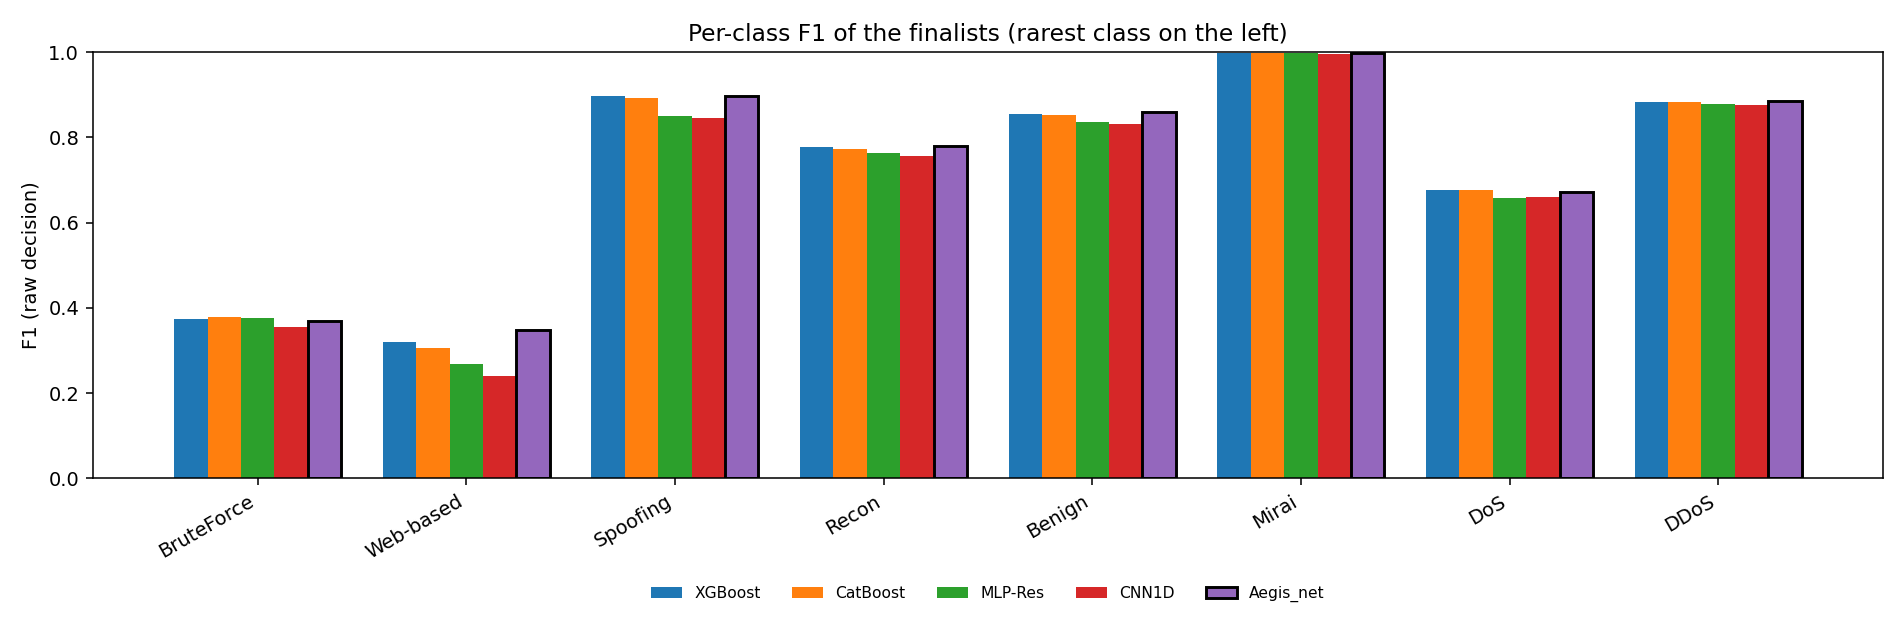

In [7]:
!python main.py --report_only --out {OUT} > /dev/null
from IPython.display import Markdown, Image, display
display(Markdown(open(f"{OUT}/results/finalists.md").read()))
display(Image(f"{OUT}/results/finalists_per_class.png"))

In [8]:
# Optional: the ablation of Aegis_net (what each ingredient is worth). Needs the cache of the run above; about 1 hour on a GPU.
import glob
CACHE = glob.glob("/content/cache_*")[0]
!python tools/ablation.py --cache {CACHE} --fit_rows 60000 --batch_size 512 --out {OUT}/results/ablation.md --variants "full" "no shrinkage (shrink=0)" "no bins at all (levels=0)" "1 member (no ensemble)"

full                               F1 raw 0.7050 +- 0.0013 | cal 0.7097 | 3 rarest classes 0.5034
no shrinkage (shrink=0)            F1 raw 0.6911 +- 0.0007 | cal 0.6949 | 3 rarest classes 0.4851
no bins at all (levels=0)          F1 raw 0.6832 +- 0.0006 | cal 0.6844 | 3 rarest classes 0.4683
1 member (no ensemble)             F1 raw 0.7059 +- 0.0013 | cal 0.7114 | 3 rarest classes 0.5069
# Aegis_net ablation (multiclass)

Seeds [42, 43, 44], fit rows 60,000, batch size 512. Rarest classes: BruteForce, Web-based, Spoofing.

| Variant | F1 macro (raw) | std | F1 macro (calibrated) | F1 of the 3 rarest classes |
|---|---|---|---|---|
| full | 0.7050 | 0.0013 | 0.7097 | 0.5034 |
| no shrinkage (shrink=0) | 0.6911 | 0.0007 | 0.6949 | 0.4851 |
| no bins at all (levels=0) | 0.6832 | 0.0006 | 0.6844 | 0.4683 |
| 1 member (no ensemble) | 0.7059 | 0.0013 | 0.7114 | 0.5069 |
